In [ ]:
import yfinance as yf
import pandas as pd

# Download Apple (AAPL) daily data from 2015 to 2025
df = yf.download("AAPL", start="2015-01-01", end="2025-01-01")

# Check the first few rows of data
print(df.head())

# Usually we only need the 'Close' price for prediction
data = df[['Close']].values

/tmp/ipykernel_4341/1382058900.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("AAPL", start="2015-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2015-01-02  24.171755  24.638255  23.733996  24.627199  212818400
2015-01-05  23.490797  24.021413  23.305082  23.941821  257142000
2015-01-06  23.493011  23.751686  23.132634  23.554916  263188400
2015-01-07  23.822437  23.921927  23.590292  23.700837  160423600
2015-01-08  24.737751  24.795235  24.032474  24.149653  237458000


In [ ]:
df=pd.DataFrame(df)

In [ ]:
print(df.head())

Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2015-01-02  24.171755  24.638255  23.733996  24.627199  212818400
2015-01-05  23.490797  24.021413  23.305082  23.941821  257142000
2015-01-06  23.493011  23.751686  23.132634  23.554916  263188400
2015-01-07  23.822437  23.921927  23.590292  23.700837  160423600
2015-01-08  24.737751  24.795235  24.032474  24.149653  237458000


In [ ]:
df1=df['High']

In [ ]:
print(data)

[[ 24.17175484]
 [ 23.49079704]
 [ 23.49301147]
 ...
 [253.74855042]
 [250.38298035]
 [248.61579895]]


In [ ]:
import matplotlib.pyplot as plt


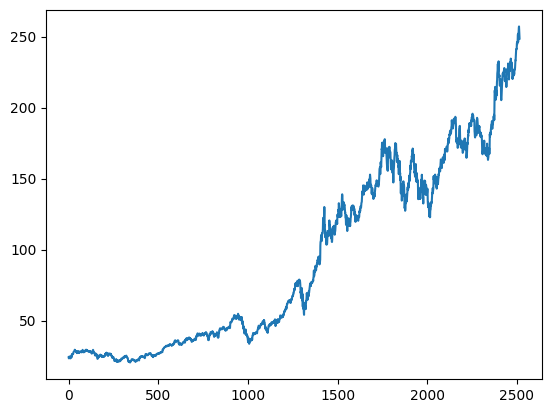

In [ ]:
plt.plot(data)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler(feature_range=(0,1))
df1=scaler.fit_transform(data).reshape(-1,1)

In [ ]:
print(df1)

[[0.01531498]
 [0.01243696]
 [0.01244631]
 ...
 [0.985608  ]
 [0.97138362]
 [0.96391473]]


In [ ]:
train_size = int(len(df1) * 0.8)
train_data = data[:train_size]
test_data  = data[train_size:]

In [ ]:
import numpy as np

def create_sequences(data, window=60):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])   # last 60 days
        y.append(data[i, 0])            # next day
    return np.array(X).reshape(-1, window, 1) , np.array(y)
window=60
X_train,y_train=create_sequences(train_data,window)
X_test,y_test=create_sequences(test_data,window)




In [ ]:
X_train.shape,y_train.shape

((1952, 60, 1), (1952,))

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout,Input


model=Sequential()
model.add(Input(shape=(60, 1)))
model.add(LSTM(50,return_sequences=True))
model.add(LSTM(50,return_sequences=True))
model.add(LSTM(50))
model.add(Dense(50))
model.add(Dense(1))
model.compile(loss="mean_squared_error",optimizer='Adam')

In [ ]:
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                  │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 60, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_14 (LSTM)                  │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,401 (208.60 KB)

 Trainable params: 53,401 (208.60 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=50,batch_size=64)

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - loss: 6385.1133 - val_loss: 30277.9863
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - loss: 3756.1582 - val_loss: 21388.2031
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 129ms/step - loss: 2536.6340 - val_loss: 16132.4580
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - loss: 2377.6858 - val_loss: 15375.0410
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - loss: 2347.8425 - val_loss: 15257.9775
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - loss: 1380.7684 - val_loss: 10150.3623
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 189ms/step - loss: 380.3872 - val_loss: 5258.7456
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - loss: 103.9985 - val_loss: 3435.2017
Epoch 9/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 138ms/step - loss: 60.0154 - val_loss: 2853.9355
Epoch 10/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - loss: 36.8701 - val_loss: 2485.3291
Epoch 11/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - loss: 31.5323 - val_loss: 2334.

In [ ]:
closes_60 = [
    100.00, 100.58, 101.72, 101.04, 102.31, 101.88, 103.02, 102.45, 103.91, 104.52,
    103.87, 104.98, 105.61, 104.72, 106.03, 106.55, 105.94, 107.12, 106.68, 108.03,
    108.71, 107.92, 109.05, 109.88, 108.94, 110.21, 111.03, 110.44, 111.92, 112.55,
    111.78, 113.04, 112.61, 114.12, 114.87, 113.95, 115.23, 115.91, 115.04, 116.52,
    117.18, 116.44, 117.85, 118.52, 117.71, 119.04, 119.88, 118.97, 120.31, 121.05,
    120.28, 121.74, 122.41, 121.63, 123.02, 123.78, 122.91, 124.35, 125.12, 124.48,
]

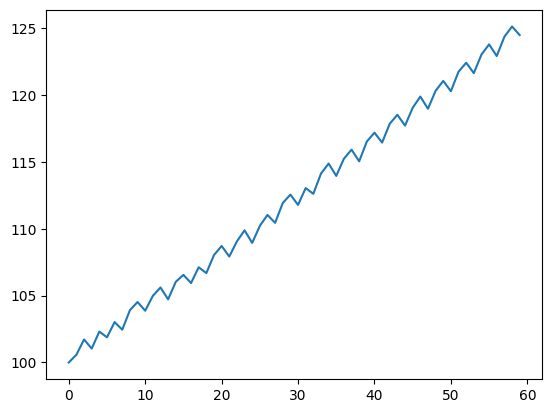

In [ ]:
plt.plot(closes_60)

In [ ]:


data = np.array(closes_60, dtype=float).reshape(-1, 1)
scaled = scaler.transform(data)

In [ ]:
import numpy as np

WINDOW=60
data = np.array(closes_60, dtype=float).reshape(-1, 1)
scaled = scaler.fit_transform(data)


x_last = scaled[-WINDOW:].reshape(1, WINDOW, 1)

pred_scaled = model.predict(x_last)


pred_price = scaler.inverse_transform(pred_scaled)[0, 0]

last_close = closes_60[-1]
print(f"Day 60 close:      ${last_close:.2f}")
print(f"Day 61 predicted:  ${pred_price:.2f}")
print(f"Change:            {(pred_price - last_close) / last_close * 100:+.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step
Day 60 close:      $124.48
Day 61 predicted:  $620.57
Change:            +398.53%


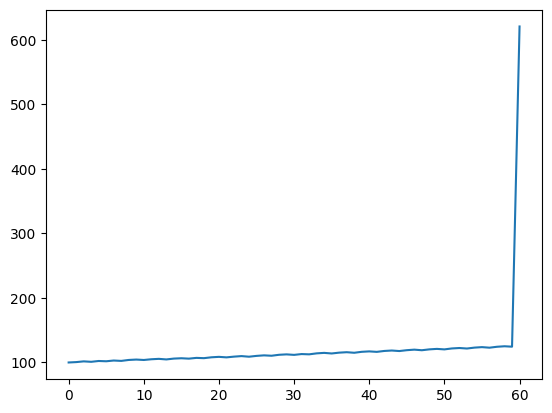

In [ ]:
closes_60.append(pred_price)
plt.plot(closes_60)